# A Nonrecombining Genealogy Control

Follow twelve DNA copies from a small nonrecombining control, separate from the
main forward population. The saved data and plots identify this control as D3 R1.
Open its inheritance record and follow the sampled copies through their parents.
The recorded tree is one realized history. The coalescent models how sample trees vary
across repeated populations, and supplies a faster way to simulate their sequence variation.


In [1]:
library(hpgR)
options(repr.plot.width = 9, repr.plot.height = 4.2, repr.plot.pointsize = 13,
        repr.plot.bg = "white", warn = 1)
blue <- "#265991"; orange <- "#D65F22"
drawFigure <- function(name, draw, width = 9, height = 3) {
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width, height = height,
            family = "Helvetica", pointsize = 13, useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) draw()
    invisible(NULL)
}


In [2]:
observed <- (function() {
  payload <- as.raw(c(
    31,139,8,0,0,0,0,0,0,3,237,90,11,80,83,87,26,190,225,33,143,128,107,17,90,87,121,180,234,80,
    138,157,106,2,136,143,181,156,90,192,170,197,117,4,186,138,15,30,18,32,211,16,35,9,145,32,58,9,144,64,
    0,161,182,174,14,35,181,181,142,69,214,173,211,93,106,91,11,69,96,215,186,157,186,221,90,237,84,4,199,245,
    209,238,206,226,128,56,44,118,107,173,251,31,76,238,197,112,239,205,189,55,1,162,211,51,147,124,255,249,207,127,
    254,243,223,123,207,255,56,55,89,235,75,16,132,27,225,225,233,78,184,185,99,114,42,124,121,88,16,51,166,192,
    199,15,56,62,120,48,89,66,82,82,146,138,34,169,104,146,138,33,169,249,36,21,75,82,11,72,106,161,133,114,
    79,150,204,163,72,9,69,74,1,38,195,71,68,80,205,98,154,213,212,97,19,69,86,149,107,36,214,25,168,14,
    89,103,224,190,23,66,159,69,188,15,4,218,166,40,110,91,3,104,200,75,126,234,96,59,160,185,94,51,23,250,
    149,177,157,159,191,12,88,115,246,219,94,49,240,119,253,148,127,247,59,61,86,234,15,95,41,4,183,38,178,161,
    69,76,130,60,229,216,198,133,172,57,214,250,109,229,68,163,121,30,110,4,245,228,220,179,229,249,0,248,86,99,
    182,31,124,188,108,68,188,65,68,153,153,47,83,19,247,55,1,30,155,66,76,248,254,156,50,108,170,101,138,150,
    52,65,75,154,160,37,77,208,146,38,104,73,19,180,164,9,218,88,248,254,217,230,162,61,173,87,140,151,241,176,
    48,125,10,100,185,242,45,202,116,121,182,133,17,144,169,204,84,232,138,101,217,233,10,153,50,87,147,151,158,165,
    178,140,248,169,182,168,229,26,16,86,83,60,223,188,76,149,98,139,70,167,26,86,252,51,163,47,145,222,103,227,
    75,129,40,33,169,43,238,60,248,74,206,250,247,18,63,6,148,239,15,191,216,9,168,46,152,222,253,19,160,214,
    255,173,176,64,236,107,185,203,55,33,61,129,116,125,95,28,186,8,184,61,234,249,157,39,1,75,250,247,5,237,
    131,241,29,27,149,254,135,1,119,150,4,45,91,15,124,253,228,12,205,32,2,140,108,221,24,3,125,211,178,143,
    78,174,128,126,69,89,241,151,55,192,39,43,67,197,179,110,3,223,60,16,88,31,134,125,53,253,153,148,15,176,
    175,206,255,251,147,231,64,174,214,184,185,211,171,157,176,248,236,77,150,253,56,146,207,117,223,138,24,120,124,228,
    199,218,30,38,61,92,248,92,236,177,229,217,91,135,139,29,246,100,185,206,183,210,116,250,28,181,135,207,253,25,
    75,121,87,180,127,12,239,63,142,133,162,123,196,131,137,33,240,62,223,13,243,93,44,17,4,58,41,17,88,41,
    210,4,45,105,130,150,50,65,75,153,160,149,72,41,50,138,34,163,41,50,134,34,231,83,100,44,69,46,160,72,
    106,53,233,60,130,204,74,238,247,136,9,73,68,81,4,125,34,242,65,41,93,27,166,225,132,179,174,105,86,30,
    78,72,121,51,253,206,4,225,132,228,209,221,29,14,168,106,201,35,238,2,110,125,78,157,254,18,160,177,175,77,
    124,7,39,20,115,211,198,221,144,72,118,205,92,144,93,167,39,44,9,67,193,176,57,153,26,219,166,230,234,88,
    76,58,232,130,58,87,123,108,215,97,75,20,92,245,177,241,236,205,23,162,135,45,144,216,20,145,163,2,132,143,
    235,6,8,159,49,12,16,227,231,167,15,44,226,110,149,82,103,230,171,20,50,88,68,109,225,248,15,115,228,202,
    220,116,141,60,95,102,97,122,221,183,101,164,199,63,82,39,205,16,20,121,124,243,143,175,65,176,137,159,59,179,
    21,159,40,179,31,251,189,73,141,131,210,172,230,68,8,101,168,224,219,233,193,160,23,105,58,245,103,119,66,16,
    218,150,218,235,25,2,88,164,10,107,90,1,252,162,166,37,193,105,208,223,158,168,91,250,25,96,201,59,111,85,
    201,49,126,158,177,61,7,198,75,46,53,72,244,208,55,4,205,62,252,58,244,13,43,103,168,255,5,88,218,48,
    120,217,23,130,91,217,179,225,65,122,232,151,117,76,59,213,219,78,160,242,245,175,28,191,133,131,159,255,157,234,
    21,208,55,182,246,247,169,0,43,229,203,51,190,7,52,167,4,44,237,128,121,230,3,171,77,157,128,85,215,63,
    205,107,3,253,213,65,102,175,19,56,72,106,154,219,182,129,220,174,255,157,159,236,3,88,231,31,218,176,3,95,
    46,14,154,162,13,4,125,227,115,162,180,39,207,101,190,149,230,26,96,233,116,178,5,28,182,224,233,108,123,28,
    189,63,116,122,232,198,132,36,2,161,246,59,210,184,158,110,184,232,225,43,55,22,207,203,89,251,147,110,111,186,
    226,126,27,111,127,180,103,15,147,126,62,247,211,158,237,182,180,35,126,192,165,232,9,113,221,162,39,228,81,60,
    21,145,36,181,154,148,90,77,74,173,38,165,86,147,82,171,73,169,213,164,212,106,82,106,53,233,120,22,116,60,
    223,0,78,69,47,73,79,158,59,3,53,69,150,108,247,19,63,0,230,150,4,255,229,123,64,69,203,190,197,161,
    128,249,67,247,18,150,224,90,103,40,34,52,23,215,54,203,62,94,180,23,176,184,80,254,205,108,192,157,51,38,
    249,158,6,212,103,61,245,222,135,128,165,191,238,115,123,27,106,139,178,213,254,147,186,96,158,233,104,101,181,9,
    248,166,191,205,137,89,133,107,146,230,85,119,123,0,171,187,150,213,124,5,114,213,151,255,243,167,119,97,188,230,
    52,113,105,29,96,237,127,139,214,94,195,230,13,31,228,174,143,246,153,7,124,105,164,79,177,197,16,33,249,211,
    158,126,190,241,96,172,242,255,72,25,190,49,206,118,92,72,94,21,210,152,238,55,31,251,199,74,222,145,253,32,
    212,30,161,123,137,107,227,187,15,88,26,109,206,154,234,186,57,107,234,35,147,179,38,60,139,48,189,190,11,136,
    251,231,234,170,87,128,64,146,199,7,123,84,128,113,135,110,204,193,184,54,35,171,225,175,128,27,99,59,250,222,
    6,204,57,245,155,254,13,56,203,236,62,246,198,85,192,87,159,254,227,0,30,47,80,232,234,74,49,94,63,151,
    216,3,89,96,199,34,69,244,143,56,171,20,230,36,253,1,176,44,45,184,123,55,100,141,242,5,169,215,90,64,
    174,252,221,189,231,3,33,123,24,211,14,54,38,1,223,52,163,245,31,253,208,55,61,221,120,163,18,155,53,156,
    61,46,216,217,202,206,246,34,62,115,248,86,159,92,215,18,114,186,114,198,201,206,158,62,71,170,109,190,167,17,
    166,123,192,22,109,233,228,232,198,184,200,179,53,62,247,154,203,137,200,222,245,10,93,131,163,126,218,108,16,224,
    186,217,32,224,225,206,6,191,188,25,118,108,11,56,231,205,176,47,74,85,127,114,181,22,242,144,82,252,221,145,
    66,64,117,115,253,222,1,200,83,133,141,3,241,248,141,176,118,107,87,90,46,96,197,98,227,237,155,192,55,199,
    63,239,85,5,125,243,111,231,100,226,255,79,84,125,81,118,238,69,200,87,181,183,181,131,231,177,238,225,124,85,
    68,140,246,59,46,31,103,52,174,121,138,235,9,136,79,21,108,69,190,215,202,102,11,215,188,225,76,123,236,233,
    38,24,226,165,175,235,198,75,223,241,137,151,19,94,218,50,189,32,17,163,172,57,155,74,123,112,105,122,185,126,
    29,254,101,186,120,240,125,77,60,160,190,51,231,184,17,74,79,131,52,100,17,254,11,148,161,38,93,42,3,151,
    46,189,40,77,88,136,75,214,3,71,18,127,192,37,106,109,56,154,2,114,149,189,186,43,133,56,20,156,238,61,
    232,166,39,44,46,95,78,179,109,248,186,56,215,82,132,203,97,212,81,253,246,198,152,66,134,51,66,25,91,120,
    112,180,141,87,41,205,84,82,137,93,55,68,136,199,189,164,154,240,104,193,116,16,246,70,17,237,123,174,222,132,
    104,176,222,175,102,241,227,128,155,39,249,189,224,13,248,234,149,47,141,248,143,149,74,195,133,196,19,128,91,15,
    94,187,125,8,176,48,109,104,229,21,136,10,21,141,232,43,79,61,97,137,10,25,252,118,140,211,100,28,217,189,
    92,146,243,72,154,75,84,19,82,148,56,163,49,121,161,183,235,122,161,183,211,189,240,151,179,134,99,79,133,238,
    172,33,226,125,214,8,70,201,175,31,56,112,214,16,140,126,39,249,243,145,232,12,15,148,190,221,51,225,68,127,
    37,218,252,68,220,180,170,43,151,144,44,101,82,249,11,171,10,145,242,112,68,241,158,79,18,208,86,221,190,111,
    94,251,213,113,84,208,97,218,223,94,30,128,212,111,180,132,12,61,155,138,182,205,206,141,186,113,43,14,233,60,
    235,155,50,239,118,162,226,83,95,159,169,143,236,69,37,199,204,183,238,45,157,142,244,109,151,30,91,25,59,132,
    12,207,173,148,204,219,99,64,134,36,34,187,161,39,18,149,134,39,133,245,138,215,160,178,127,47,239,216,114,97,
    15,42,159,177,162,62,114,127,55,50,102,183,108,152,155,60,27,25,101,254,57,226,99,205,200,120,244,101,217,194,
    229,74,84,241,76,68,222,146,184,2,84,241,117,108,73,234,155,58,84,21,170,240,136,73,110,68,213,173,97,245,
    11,59,148,104,215,157,185,157,71,221,114,81,221,147,69,3,155,130,231,223,15,121,162,213,220,220,114,20,205,86,
    175,19,52,52,223,102,175,246,23,26,54,133,204,19,34,47,180,112,17,114,238,225,114,94,179,119,190,18,98,59,
    157,45,108,99,92,11,93,103,173,203,215,30,103,92,55,219,51,26,73,179,221,127,174,107,177,141,59,226,31,66,
    199,248,220,79,186,248,64,23,47,152,124,159,173,49,61,3,46,205,222,117,208,140,211,150,44,193,174,91,178,4,
    143,251,193,129,36,31,190,127,147,60,140,213,24,173,185,110,241,228,211,142,39,159,118,60,249,180,227,163,241,220,
    255,3,7,24,94,74,208,58,0,0
  ))
  con <- gzcon(rawConnection(payload))
  on.exit(close(con))
  readRDS(con)
})()


## Follow the control's sampled copies

The control was generated at size 80, then 20 for 40 generations, then 80 for 20 generations.
Rebuild the region using its original parent-map and mutation seeds. Verify that its sequences
and mutation positions exactly match the public observations before examining its tree.
This opens a simulation record; it does not estimate ancestry from those sequences.

Ages count generations backward from the fixed sample at time zero.
If ancestors have not yet met at the start of the 60-generation record, the generator
continues older discrete Wright–Fisher parent maps at the ancestral size.


In [3]:
sizes <- c(80L, rep(20L, 40L), rep(80L, 20L))
record <- pgRecordAncestry(sizes, length_bp = 1000, n = 12L,
    ancestry_seed = pgRegionSeed(817900L, 1L))
mutation <- pgMutateAncestry(record, mu = 2e-5,
    mutation_seed = pgRegionSeed(917900L, 1L, mutation = TRUE))
stopifnot(identical(mutation$haplotypes,
                    unname(observed$D3$regions[[1]]$haplotypes)),
          identical(mutation$positions_bp, observed$D3$regions[[1]]$positions_bp),
          identical(pgReplay(record, mutation$mutations), mutation$haplotypes))
tree <- pgCompressTree(record, sample_ids = observed$D3$sample_ids)
tree_summary <- pgTreeSummaries(tree)
print(c(region = "D3 R1", segregating_sites = ncol(mutation$haplotypes),
        pair_age = tree_summary$pair_time, root_age = tree_summary$TMRCA,
        final_two_lineage_interval = tree_summary$last_two_wait))


                    region          segregating_sites                   pair_age                   root_age 
                   "D3 R1"                       "10"                       "66"                       "66" 
final_two_lineage_interval 
                      "38" 


In [4]:
treePositions <- function(tree) {
    children <- split(tree$edges$child, tree$edges$parent)
    leaves <- function(id) {
        child <- children[[as.character(id)]]
        if (!length(child)) return(id)
        unlist(lapply(child, leaves), use.names = FALSE)
    }
    ordered <- leaves(tree$root)
    x <- setNames(numeric(nrow(tree$nodes)), tree$nodes$id)
    x[as.character(ordered)] <- seq_along(ordered)
    for (id in tree$nodes$id[order(tree$nodes$time)]) {
        child <- children[[as.character(id)]]
        if (length(child)) x[as.character(id)] <- mean(x[as.character(child)])
    }
    x
}
drawRecordedTree <- function(tree) {
    x <- treePositions(tree)
    age <- setNames(tree$nodes$time, tree$nodes$id)
    summary <- pgTreeSummaries(tree)
    plot(NA, xlim = c(.5, tree$n + 3), ylim = c(0, max(60, summary$TMRCA) * 1.12),
         xaxt = "n", xlab = "Sampled DNA copy", ylab = "Generations before sampling")
    if (summary$TMRCA > 60) {
        abline(h = 60, col = "gray65", lty = 3)
        text(3.5, 60, "Record start", pos = 1, cex = .85, col = "gray45")
    }
    for (i in seq_len(nrow(tree$edges))) {
        parent <- as.character(tree$edges$parent[i]); child <- as.character(tree$edges$child[i])
        highlight <- any(1:2 %in% tree$descendants[[child]]) &&
            age[child] < summary$pair_time
        color <- if (highlight) blue else "gray55"
        segments(x[child], age[child], x[child], age[parent], col = color, lwd = 2)
        segments(x[child], age[parent], x[parent], age[parent], col = color, lwd = 2)
    }
    samples <- as.character(tree$sample_nodes)
    axis(1, x[samples], tree$sample_ids, tick = FALSE, cex.axis = .85)
    shared <- which(vapply(tree$descendants, function(d) all(1:2 %in% d), logical(1)))
    pair_node <- names(tree$descendants)[shared[which.min(age[shared])]]
    points(x[pair_node], summary$pair_time, pch = 18, col = blue, cex = 1.2)
    points(x[as.character(tree$root)], summary$TMRCA, pch = 16, col = orange, cex = 1.1)
    legend("topright", c("S1/S2 ancestral paths", paste("Sample MRCA:", summary$TMRCA)),
           col = c(blue, orange), lty = c(1, NA), pch = c(NA, 16), bty = "n",
           cex = .85, y.intersp = 1.8, inset = .02)
}


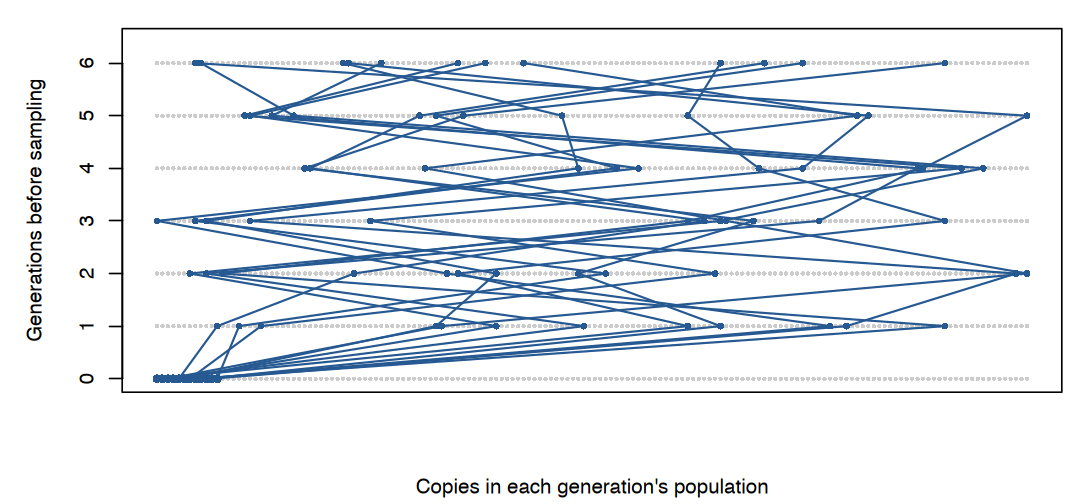

In [5]:
drawFigure("p5_recorded_paths", function() {
    par(mar = c(4.3, 4.7, 1.1, .7), bg = "white")
    ages <- 0:6
    pools <- lapply(ages, function(t) record$nodes$id[record$nodes$time == t])
    plot(NA, xlim = c(1, 160), ylim = c(0, 6.4), xaxt = "n",
         xlab = "Copies in each generation's population", ylab = "Generations before sampling")
    for (i in seq_along(pools)) points(seq_along(pools[[i]]), rep(ages[i], 160),
                                      pch = 16, cex = .35, col = "gray80")
    parent <- setNames(record$edges$parent, record$edges$child)
    copies <- record$sample_nodes
    for (i in seq_len(6)) {
        older <- unname(parent[as.character(copies)])
        segments(match(copies, pools[[i]]), i - 1, match(older, pools[[i + 1]]), i,
                 col = blue, lwd = 1.3)
        points(match(older, pools[[i + 1]]), rep(i, 12), pch = 16, col = blue, cex = .6)
        copies <- older
    }
    points(match(record$sample_nodes, pools[[1]]), rep(0, 12),
           pch = 16, col = blue, cex = .8)
})


## Read ages and branch lengths on the recorded tree

Collapse nodes with a single child in the sampled genealogy into branches, retaining
the branching nodes and all sample identities. The tree preserves simultaneous
mergers and nodes with more than two children when they occur in the discrete record.

$T_{\rm pair}$ is the age of S1 and S2's common ancestor. $T_{\rm MRCA}$ is the root age
for all twelve copies. A branch length is its parent's age minus its child's age.
In the coalescent formulas below, $T_k$ is instead the **duration** with $k$ lineages.
With two sampled copies only, the root age and the final two-lineage duration coincide.


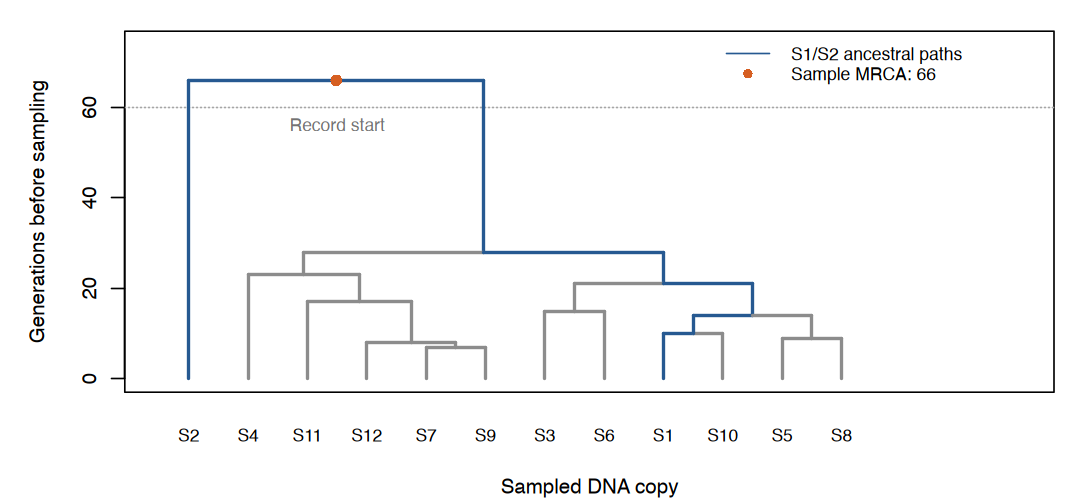

In [6]:
drawFigure("p5_recorded_tree", function() {
    par(mar = c(4.3, 4.8, 1.2, 1), bg = "white")
    drawRecordedTree(tree)
})
stopifnot(sum(tree_summary$branch_generations) == tree_summary$total_branch_length,
          sum(tree_summary$waiting_times) == tree_summary$TMRCA)


## Founder labels and allele differences

Track founder-copy IDs and binary alleles through the same parental draws.
For two distinct sampled copies, $F_t$ measures shared founder identity and
$H_t$ measures an allele difference. Across independent runs,
$$E(1-F_t)=E(H_t)/H_0=(1-1/(2N))^t.$$
The example uses $N=40$, 60 generations and 200 independent records.


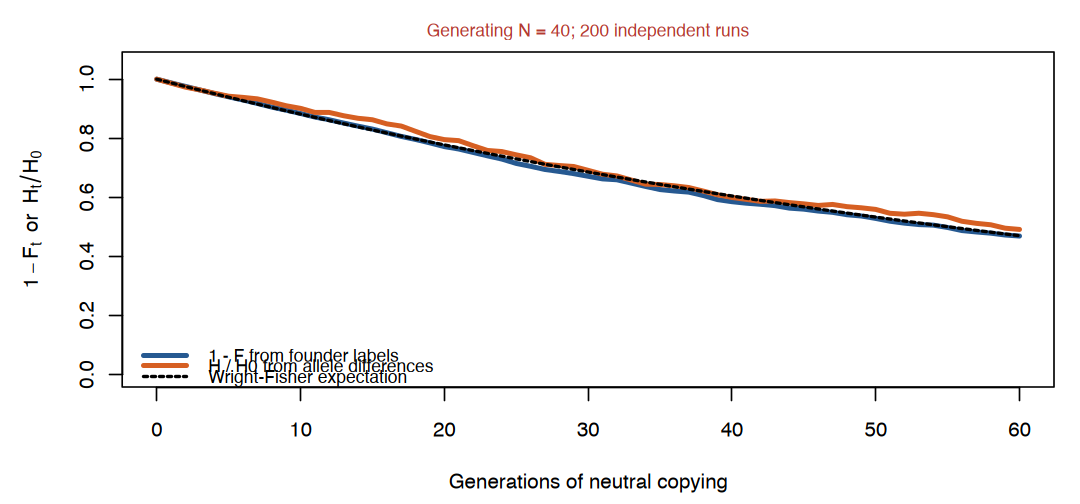

In [7]:
founder_check <- founderDiversityExample()
drawFigure("founder_ibd_diversity_check", function() {
    x <- founder_check$summary
    par(mar = c(4.5, 4.7, 2, 1), bg = "white")
    plot(x$generation, x$nonIBD, type = "l", col = blue, lwd = 3,
         ylim = c(0, 1.05), xlab = "Generations of neutral copying",
         ylab = expression(1-F[t]~~"or"~~H[t]/H[0]))
    lines(x$generation, x$diversityRatio, col = orange, lwd = 3)
    lines(x$generation, x$expectation, lty = 2, lwd = 2)
    legend("bottomleft", c("1 - F from founder labels", "H / H0 from allele differences",
        "Wright-Fisher expectation"), col = c(blue, orange, "black"),
        lty = c(1, 1, 2), lwd = c(3, 3, 2), bty = "n", cex = .85)
    mtext("Generating N = 40; 200 independent runs", side = 3, line = .5,
          col = "#B33B32", cex = .85)
}, height = 3.8)


## Simulate the sample's ancestors

Two distinct lineages choose the same parent copy with probability $1/(2N)$ in each
discrete generation. For constant size, their waiting time has geometric survival
$\Pr(T_{\rm pair}>t)=(1-1/(2N))^t$. Its mean is $2N$ generations.

The large-population **Kingman coalescent** replaces these trials with exponential
waiting times. With $k$ lineages, wait at rate $\binom{k}{2}/(2N_e)$, then join a uniformly
chosen pair. Repeat to the sample MRCA. A branch of length $b$ receives a Poisson number
of mutations with mean $\mu Lb$; its descendants inherit those mutations.
We compare new random samples from these models, rather than expecting the same tree.


### Two DNA copies in a longer region

Use $N_e=1000$, a nonrecombining one-megabase region and $\mu=10^{-8}$ per base per generation.
The mean wait should be 2,000 generations. Two branches give an average of
$2\mu L\,E(T_{\rm pair})=40$ differences. Individual pairs have a broad distribution.


        mean_wait        model_wait  mean_differences model_differences 
       1996.55233        2000.00000          39.95433          40.00000 


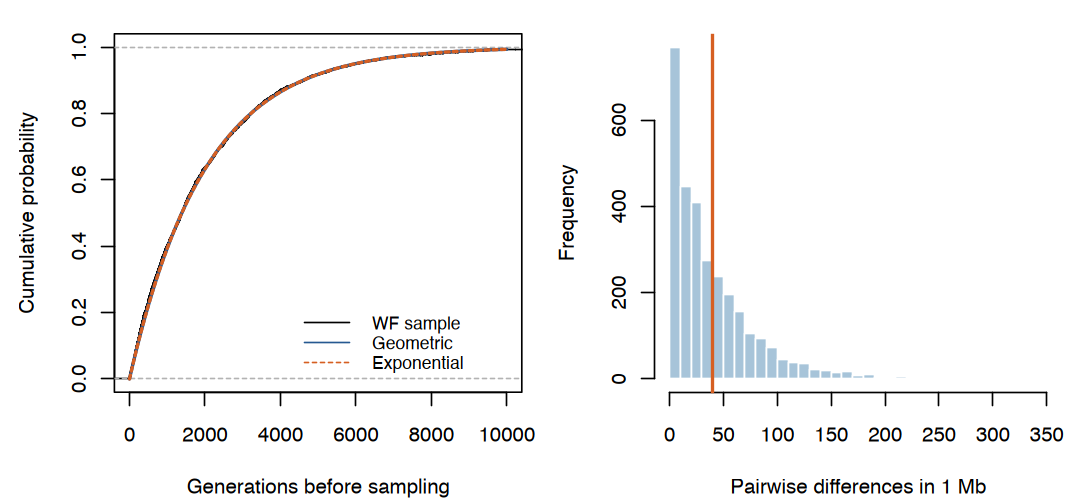

In [8]:
set.seed(9001)
Ne <- 1000
mu <- 1e-8
L <- 1e6
T2 <- rgeom(3000, prob = 1 / (2 * Ne)) + 1
differences <- rpois(length(T2), lambda = 2 * mu * L * T2)
stopifnot(all(T2 >= 1), all(differences >= 0))
print(c(mean_wait = mean(T2), model_wait = 2 * Ne,
        mean_differences = mean(differences), model_differences = 4 * Ne * mu * L))
drawFigure("p5_pair_waiting", function() {
    par(mfrow = c(1, 2), mar = c(4.3, 4.4, 1.3, .7), bg = "white")
    plot(ecdf(T2), xlim = c(0, 10000), verticals = TRUE, do.points = FALSE,
         xlab = "Generations before sampling", ylab = "Cumulative probability", main = "")
    curve(1 - (1 - 1 / (2 * Ne))^floor(x), add = TRUE, col = blue, lwd = 2)
    curve(1 - exp(-x / (2 * Ne)), add = TRUE, col = orange, lty = 2, lwd = 2)
    legend("bottomright", c("WF sample", "Geometric", "Exponential"),
           col = c("black", blue, orange), lty = c(1, 1, 2), bty = "n", cex = .85,
           y.intersp = 1.8, inset = c(.02, .04))
    hist(differences, breaks = 35, col = "#A7C4D9", border = "white",
         xlab = "Pairwise differences in 1 Mb", main = "")
    abline(v = 4 * Ne * mu * L, col = orange, lwd = 2)
})


## Compare entire genealogies under matched assumptions

Return to the twelve-copy, independent 1-kb region design. Compare constant $N=80$
with the same model at $N=800$. Set $\mu=2\times10^{-5}$ and $2\times10^{-6}$ respectively,
so $4N\mu L=6.4$ in both. This keeps expected sequence diversity comparable as the
sampled fraction becomes smaller. These are scaled simulation parameters.

For each size, generate 600 independent discrete Wright–Fisher genealogies and 600
independent Kingman genealogies. The discrete sampler draws each retained lineage's
parent independently every generation. It has the same marginal law as full population
maps, while skipping copies that cannot affect the sample.
Both use infinite sites and the same conditional Poisson mutation process.

We expect close tree-age and sequence summaries, especially at larger size.
Recent discrete generations can still contain several mergers at once.


In [9]:
matched_80 <- matchedDraws(80L, 2e-5, base_seed = 7814900L)


   N       model pair_time  TMRCA branch_length pi_region     S multifurcation
  80 Discrete WF     158.2  284.2         951.6     6.060 18.81           0.10
 800 Discrete WF    1536.1 2865.5        9437.2     6.207 18.70           0.01
  80     Kingman     151.8  284.4         941.3     6.121 18.64           0.00
 800     Kingman    1549.0 2909.2        9590.1     6.236 18.88           0.00


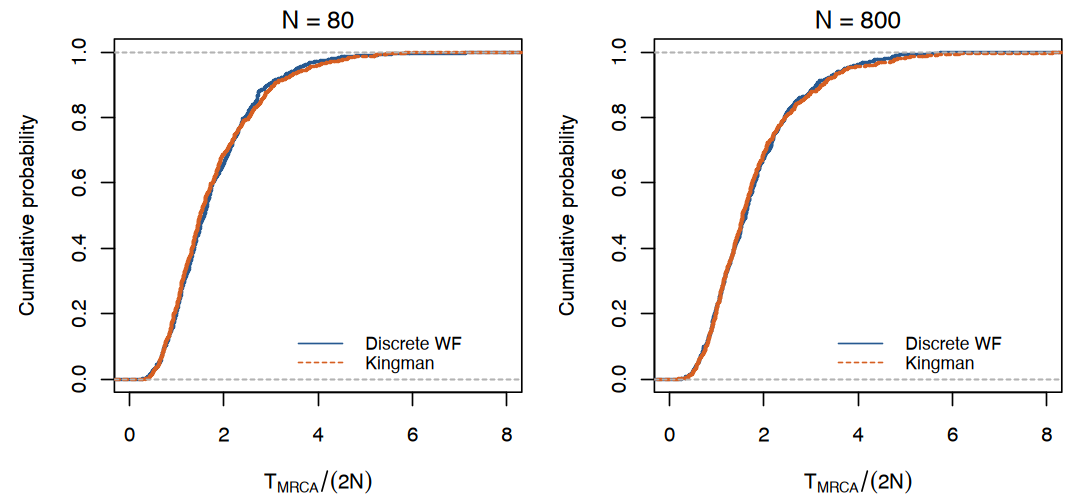

In [10]:
matched_800 <- matchedDraws(800L, 2e-6, base_seed = 7914900L)
matched <- rbind(matched_80$results, matched_800$results)
stopifnot(!anyDuplicated(c(matched$ancestry_seed, matched$mutation_seed)))
report <- aggregate(cbind(pair_time, TMRCA, branch_length, pi_region, S,
                          multifurcation) ~ N + model, matched, mean)
print(report, row.names = FALSE, digits = 4)
drawFigure("p5_matched_genealogies", function() {
    par(mfrow = c(1, 2), mar = c(4.3, 4.4, 1.5, .7), bg = "white")
    for (N in c(80, 800)) {
        wf <- matched$TMRCA[matched$N == N & matched$model == "Discrete WF"] / (2 * N)
        coal <- matched$TMRCA[matched$N == N & matched$model == "Kingman"] / (2 * N)
        plot(ecdf(wf), do.points = FALSE, verticals = TRUE, col = blue, lwd = 2,
             xlim = c(0, 8), xlab = expression(T[MRCA] / (2 * N)),
             ylab = "Cumulative probability", main = paste("N =", N))
        lines(ecdf(coal), do.points = FALSE, verticals = TRUE, col = orange, lty = 2, lwd = 2)
        legend("bottomright", c("Discrete WF", "Kingman"), col = c(blue, orange),
               lty = c(1, 2), bty = "n", cex = .85, y.intersp = 1.8, inset = c(.02, .04))
    }
})


### Check recent mergers as well as the root age

Under discrete copying, the first generation with a merger can lose several lineages.
For example, two separate pairs can choose two shared parents in that generation.
Kingman joins one pair at each event. More than two children and exact ties between
distinct merger times are features of the discrete model.

With $n$ distinct lineages, the exact probability of no merger in one generation is
$\prod_{j=0}^{n-1}(1-j/(2N))$. One minus this product gives the probability of at least
one merger, approximated by $\binom n2/(2N)$ for large $N$.
A small sample fraction alone does not guarantee
that the total merger probability per generation is small.


   N fraction_multiple_at_first_change predicted_multiple_at_first_change any_next_generation pair_rate
  80                           0.17500                            0.15814             0.34476   0.41250
 800                           0.01333                            0.01612             0.04051   0.04125


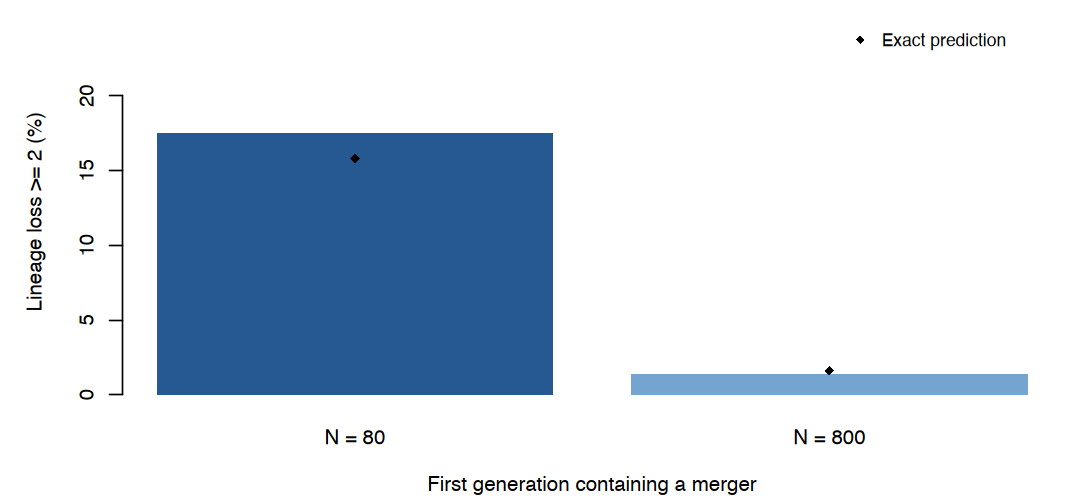

In [11]:
first_merger_report <- do.call(rbind, lapply(c(80, 800), function(N) {
    x <- matched[matched$N == N & matched$model == "Discrete WF", ]
    no_merger <- prod(1 - (0:11) / (2 * N))
    one_pair <- choose(12, 2) / (2 * N) * prod(1 - (0:10) / (2 * N))
    data.frame(N = N, fraction_multiple_at_first_change = mean(x$first_loss >= 2),
        predicted_multiple_at_first_change = (1 - no_merger - one_pair) / (1 - no_merger),
        any_next_generation = 1 - no_merger,
        pair_rate = choose(12, 2) / (2 * N))
}))
print(first_merger_report, row.names = FALSE, digits = 4)
drawFigure("p5_recent_mergers", function() {
    par(mar = c(4.2, 4.7, 1.1, .7), bg = "white")
    values <- 100 * first_merger_report$fraction_multiple_at_first_change
    mid <- barplot(values, names.arg = c("N = 80", "N = 800"), ylim = c(0, max(values) * 1.4),
            ylab = "Lineage loss >= 2 (%)", col = c(blue, "#75A4D1"), border = NA)
    points(mid, 100 * first_merger_report$predicted_multiple_at_first_change, pch = 18)
    legend("topright", "Exact prediction", pch = 18, bty = "n", cex = .85)
    mtext("First generation containing a merger", 1, line = 2.8)
}, width = 5, height = 3.1)


## Do the models generate similar sequence variation?

Use the same $\mu$, region length and sample size within each comparison.
A branch with $i$ sampled descendants contributes its mutations to SFS bin $i$.
The Kingman expectation is $E(\xi_i)=4N_e\mu L/i$ under constant size and infinite sites.
Its expected mean pairwise difference is $4N_e\mu L=6.4$ per region in both designs.
The plots compare repeated datasets, rather than a single favorable pair of trees.


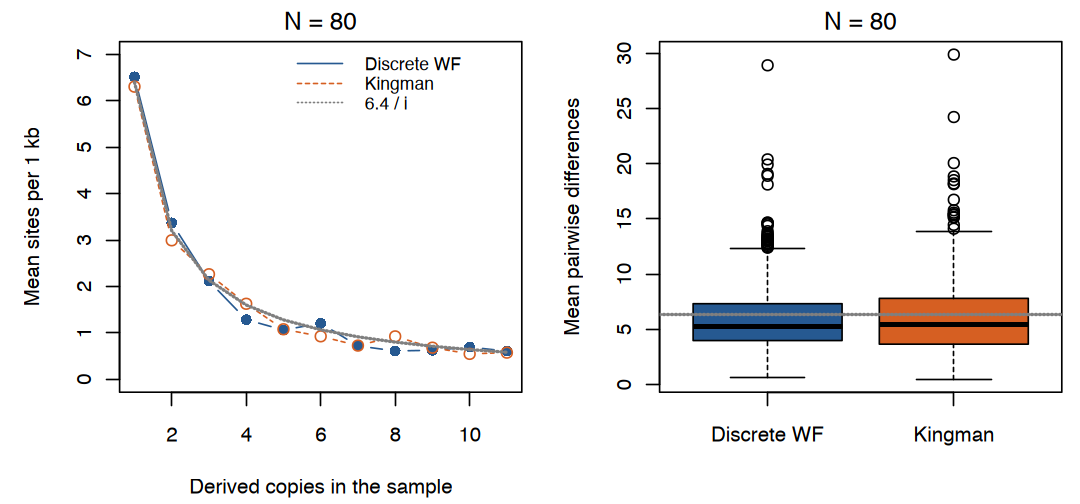

In [12]:
drawFigure("p5_matched_sequences", function() {
    par(mfrow = c(1, 2), mar = c(4.3, 4.6, 1.6, .7), bg = "white")
    means <- rbind(colMeans(matched_80$sfs[1:600, ]), colMeans(matched_80$sfs[601:1200, ]))
    matplot(1:11, t(means), type = "b", pch = c(16, 1), lty = c(1, 2),
            col = c(blue, orange), xlab = "Derived copies in the sample",
            ylab = "Mean sites per 1 kb", ylim = c(0, 7), main = "N = 80")
    lines(1:11, 6.4 / (1:11), col = "gray50", lty = 3, lwd = 2)
    legend("topright", c("Discrete WF", "Kingman", "6.4 / i"),
           col = c(blue, orange, "gray50"), lty = c(1, 2, 3), bty = "n", cex = .85,
           y.intersp = 1.8, inset = .02)
    boxplot(pi_region ~ model, data = matched[matched$N == 80, ],
            col = c(blue, orange), ylab = "Mean pairwise differences", xlab = "", main = "N = 80")
    abline(h = 6.4, lty = 3, col = "gray50", lwd = 2)
})


## Compare size and ancestral-time estimates

The simulations above also supply the segregating-site count $S$, pairwise
diversity $\pi_L$ and the differences $M$ between copies 1 and 2.
Use $\widehat H=\pi_L/L$ to compare $\widehat N_{e,H}=\widehat H/(4\mu)$ with
$\widehat N_{e,W}=S/(4\mu L\sum_{i=1}^{n-1}1/i)$ in the same runs.
Each model has 600 independent regions at each generating size.

For the fixed pair, $M\mid T_2\sim\mathrm{Poisson}(2\mu LT_2)$ gives
$\widehat T_2=M/(2\mu L)$. The red diagonal compares each estimate
with its own recorded ancestral time. Exact Poisson intervals quantify
the sequence-count uncertainty conditional on that time.


Pairwise Poisson interval coverage: 0.975 


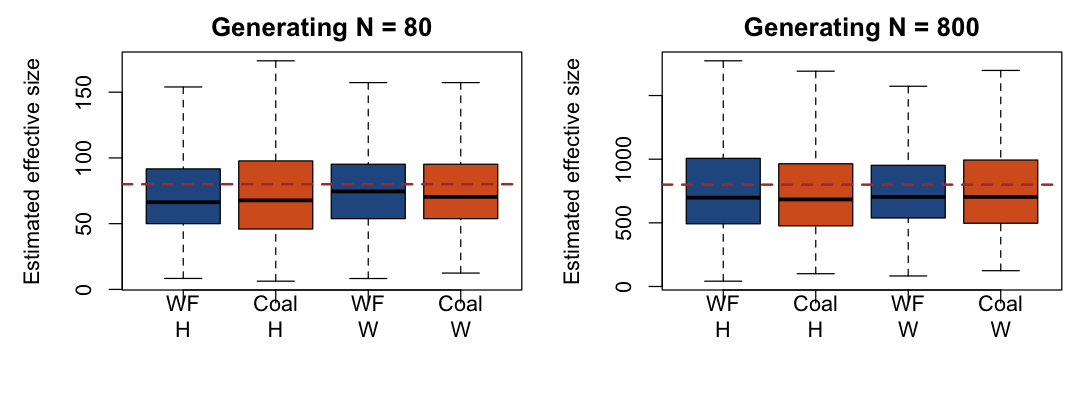

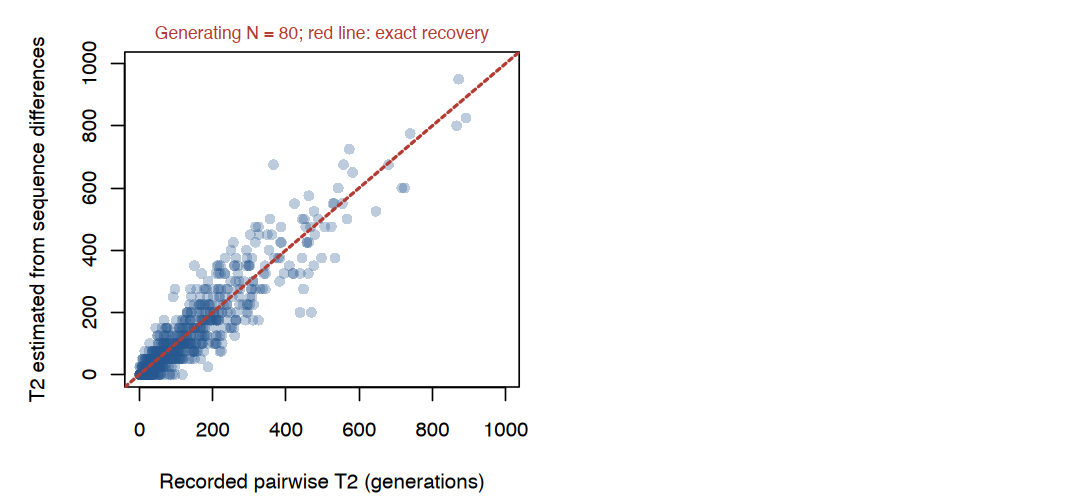

In [13]:
drawFigure("forward_coalescent_comparison", function() {
    par(mfrow = c(1, 2), mar = c(5, 4.7, 2, .7), bg = "white")
    for (N in c(80, 800)) {
        mu <- if (N == 80) 2e-5 else 2e-6
        wf <- matched[matched$N == N & matched$model == "Discrete WF", ]
        coal <- matched[matched$N == N & matched$model == "Kingman", ]
        scale <- 4 * mu * 1000
        harmonic <- sum(1 / 1:11)
        boxplot(list(wf$pi_region / scale, coal$pi_region / scale,
            wf$S / (harmonic * scale), coal$S / (harmonic * scale)),
            names = c("WF\nH", "Coal\nH", "WF\nW", "Coal\nW"),
            col = c(blue, orange, blue, orange), outline = FALSE,
            ylab = "Estimated effective size", main = paste("Generating N =", N))
        abline(h = N, lty = 2, col = "#B33B32", lwd = 2)
    }
}, height = 3.5)

clock <- matched[matched$N == 80 & matched$model == "Kingman", ]
clock$estimate <- clock$pair_differences / (2 * 2e-5 * 1000)
clock$lower <- ifelse(clock$pair_differences == 0, 0,
    qchisq(.025, 2 * clock$pair_differences) / (4 * 2e-5 * 1000))
clock$upper <- qchisq(.975, 2 * (clock$pair_differences + 1)) / (4 * 2e-5 * 1000)
drawFigure("pairwise_time_recovery", function() {
    par(mar = c(4.5, 4.8, 2, .8), bg = "white")
    maximum <- max(clock$pair_time, clock$estimate) * 1.05
    plot(clock$pair_time, clock$estimate, pch = 16,
         col = adjustcolor(blue, .3), xlim = c(0, maximum), ylim = c(0, maximum),
         xlab = "Recorded pairwise T2 (generations)",
         ylab = "T2 estimated from sequence differences")
    abline(0, 1, lty = 2, lwd = 2, col = "#B33B32")
    mtext("Generating N = 80; red line: exact recovery", side = 3, line = .4,
          col = "#B33B32", cex = .85)
}, width = 5.2, height = 4.2)
cat("Pairwise Poisson interval coverage:",
    mean(clock$lower <= clock$pair_time & clock$pair_time <= clock$upper), "\n")


The control's recorded tree describes the twelve observed sequences.
Its ancestral ages and branches can now be checked directly.
Each new simulation draws another genealogy. Matching sequence distributions across
these simulations checks the approximation used to replace population copying with
a model of the sample's ancestors. Recent discrete merger events retain finite-population
features even when broad tree-age and diversity summaries look similar.

Recovering this particular tree from its DNA alone is a further inference problem.

Sources: Pritchard, [Sec. 2.2](https://web.stanford.edu/group/pritchardlab/HGbook.html),
Figs. 2.16–2.20 and Eqs. 2.14, 2.20–2.26;
Gorroochurn, *Notes on Population Genetics*, Secs. 8.10–8.12.
